In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df =pd.read_excel("Medical Insurance Cost Prediction.xlsm")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [5]:
df.shape

(1338, 7)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df.drop_duplicates(inplace=True)        

In [10]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
#   Visualize the distribution of each feature
#	Understand correlations (especially with the target variable)
#	Check for variables distributions.
#	Summarize insights from EDA

In [11]:
numerical = df.select_dtypes(include=['int64', 'float64'])

In [12]:
numerical.corr()

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


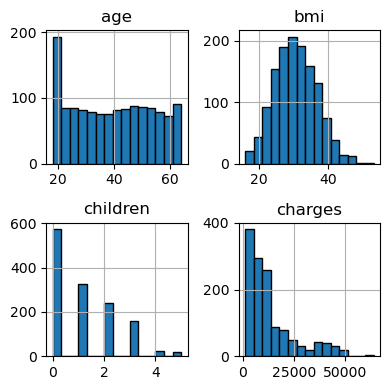

In [13]:
numerical.hist(figsize=(4, 4), bins=15 , edgecolor='black')
plt.tight_layout()
plt.show()


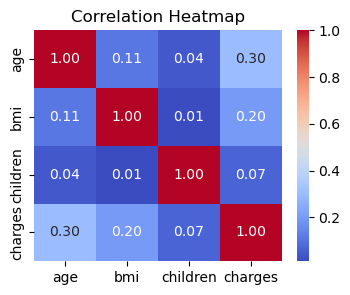

In [9]:
plt.figure(figsize=(4, 3))
sns.heatmap(numerical.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

In [14]:
numerical.skew()

age         0.054781
bmi         0.283914
children    0.937421
charges     1.515391
dtype: float64

In [15]:
df.value_counts()

age  sex     bmi     children  smoker  region     charges    
18   female  20.790  0         no      southeast  1607.51010     1
48   female  27.360  1         no      northeast  9447.38240     1
             25.850  3         yes     southeast  24180.93350    1
             22.800  0         no      southwest  8269.04400     1
47   male    47.520  1         no      southeast  8083.91980     1
                                                                ..
31   female  25.740  0         no      southeast  3756.62160     1
             23.600  2         no      southwest  4931.64700     1
             21.755  0         no      northwest  4134.08245     1
30   male    44.220  2         no      southeast  4266.16580     1
64   male    40.480  0         no      southeast  13831.11520    1
Name: count, Length: 1337, dtype: int64

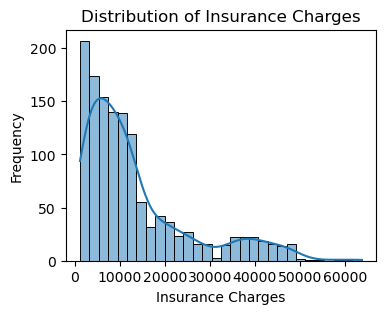

In [16]:
plt.figure(figsize=(4, 3))

sns.histplot(data=df, x='charges', bins=30, kde=True)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")

plt.show()

In [17]:
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (1337, 7)
Duplicate rows: 0


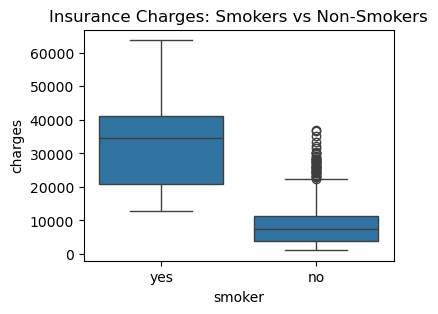

In [22]:
plt.figure(figsize=(4, 3))
sns.boxplot(data=df, x='smoker', y='charges')
plt.title("Insurance Charges: Smokers vs Non-Smokers")
plt.show()

In [23]:
df["smoker"].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

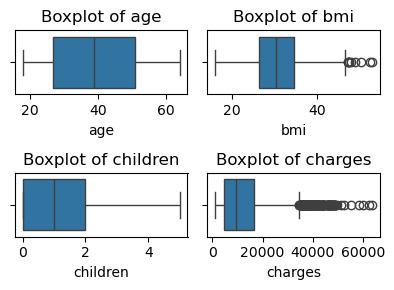

In [25]:
plt.figure(figsize=(4, 3))

for i, col in enumerate(numerical, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [18]:

Q1 = numerical.quantile(0.25)
Q3 = numerical.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR    
outlier = ((numerical < lower_bound) | (numerical > upper_bound)).sum()
print("Outliers in each numerical column:")
print(outlier)


Outliers in each numerical column:
age           0
bmi           9
children      0
charges     139
dtype: int64


In [19]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [21]:
categorical = df.select_dtypes(include=['object'])
categorical.head()

,sex,smoker,region
0,female,yes,southwest
1,male,no,southeast
2,male,no,southeast
3,male,no,northwest
4,male,no,northwest


In [22]:
categorical.columns

Index(['sex', 'smoker', 'region'], dtype='object')

In [24]:
categorical.nunique()

sex       2
smoker    2
region    4
dtype: int64

In [26]:

for col in categorical.columns:
    print(col, ":", categorical[col].unique())

sex : ['female' 'male']
smoker : ['yes' 'no']
region : ['southwest' 'southeast' 'northwest' 'northeast']


In [31]:
df = pd.get_dummies(df,columns= categorical.columns,drop_first=  True ,dtype=int)
df.head()


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [32]:
df.columns

Index(['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes',
       'region_northwest', 'region_southeast', 'region_southwest'],
      dtype='object')

In [33]:
df.shape

(1337, 9)

In [35]:
numerical.skew()

age         0.054781
bmi         0.283914
children    0.937421
charges     1.515391
dtype: float64

In [38]:
df["charges_log"] = np.log1p(df["charges"]) 
df["charges_log"].skew()


np.float64(-0.08955835073325419)

In [42]:
X = df.drop(columns=['charges', 'charges_log'])
y = df['charges_log']
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1337, 8)
Target shape: (1337,)


In [44]:
from sklearn.model_selection import train_test_split

In [46]:
X_train , X_test , Y_train , Y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Y_train:", Y_train.shape)
print("Y_test:", Y_test.shape)


X_train: (1069, 8)
X_test: (268, 8)
Y_train: (1069,)
Y_test: (268,)


In [50]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)


X_train_scaled shape: (1069, 8)
X_test_scaled shape: (268, 8)


In [62]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr = LinearRegression()

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
n = X_test.shape[0]
p = X_test.shape[1]

r2 = r2_score(y_test, y_pred_lr)

adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
print("linear regression model trained successfully.")
print("MAE:", mean_absolute_error(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("R2 Score:", r2_score(y_test, y_pred_lr))
print("R² Score:", r2)
print("Adjusted R² Score:", adjusted_r2)



linear regression model trained successfully.
MAE: 4177.0455610363215
RMSE: 5956.3428943635845
R2 Score: 0.8069287081198014
R² Score: 0.8069287081198014
Adjusted R² Score: 0.8009651160926139


In [56]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

n = X_test.shape[0]
p = X_test.shape[1]

r2_dt = r2_score(y_test, y_pred_dt)

adjusted_r2_dt = 1 - (
    (1 - r2_dt) * (n - 1) / (n - p - 1)
)

print("Decision Tree Results")
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))
print("R² Score:", r2_dt)
print("Adjusted R² Score:", adjusted_r2_dt)




Decision Tree Results
MAE: 2730.629848988806
RMSE: 5769.014181311075
R² Score: 0.8188820336469307
Adjusted R² Score: 0.8132876563078397


In [57]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)

adjusted_r2_rf = 1 - ((1 - r2_rf) * (n - 1) / (n - p - 1))

print("Random Forest Regressor")
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R² Score:", r2_rf)
print("Adjusted R² Score:", adjusted_r2_rf)

Random Forest Regressor
MAE: 2637.994548149254
RMSE: 4702.446229154652
R² Score: 0.8796611113027271
Adjusted R² Score: 0.8759440799916144


In [58]:
from sklearn.svm import SVR

svr = SVR(kernel='rbf')

svr.fit(X_train_scaled, y_train)

y_pred_svr = svr.predict(X_test_scaled)

r2_svr = r2_score(y_test, y_pred_svr)

adjusted_r2_svr = 1 - ((1 - r2_svr) * (n - 1) / (n - p - 1))

print("Support Vector Regression")
print("MAE:", mean_absolute_error(y_test, y_pred_svr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_svr)))
print("R² Score:", r2_svr)
print("Adjusted R² Score:", adjusted_r2_svr)

Support Vector Regression
MAE: 9264.975876468776
RMSE: 14417.272276881557
R² Score: -0.13116125440762327
Adjusted R² Score: -0.16610059817310985


In [59]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

r2_knn = r2_score(y_test, y_pred_knn)

adjusted_r2_knn = 1 - ((1 - r2_knn) * (n - 1) / (n - p - 1))

print("KNN Regressor")
print("MAE:", mean_absolute_error(y_test, y_pred_knn))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_knn)))
print("R² Score:", r2_knn)
print("Adjusted R² Score:", adjusted_r2_knn)

KNN Regressor
MAE: 3474.067730899254
RMSE: 5470.795560201992
R² Score: 0.8371231762189264
Adjusted R² Score: 0.8320922318550322


In [60]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(random_state=42)

gbr.fit(X_train, y_train)

y_pred_gbr = gbr.predict(X_test)

r2_gbr = r2_score(y_test, y_pred_gbr)

adjusted_r2_gbr = 1 - ((1 - r2_gbr) * (n - 1) / (n - p - 1))

print("Gradient Boosting Regressor")
print("MAE:", mean_absolute_error(y_test, y_pred_gbr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_gbr)))
print("R² Score:", r2_gbr)
print("Adjusted R² Score:", adjusted_r2_gbr)

Gradient Boosting Regressor
MAE: 2517.4678305027105
RMSE: 4268.283017604774
R² Score: 0.9008563879867466
Adjusted R² Score: 0.8977940370365303


In [61]:
from sklearn.ensemble import AdaBoostRegressor

ada = AdaBoostRegressor(random_state=42)

ada.fit(X_train, y_train)

y_pred_ada = ada.predict(X_test)

r2_ada = r2_score(y_test, y_pred_ada)

adjusted_r2_ada = 1 - ((1 - r2_ada) * (n - 1) / (n - p - 1))

print("AdaBoost Regressor")
print("MAE:", mean_absolute_error(y_test, y_pred_ada))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ada)))
print("R² Score:", r2_ada)
print("Adjusted R² Score:", adjusted_r2_ada)

AdaBoost Regressor
MAE: 3942.5757114614007
RMSE: 4866.599299138523
R² Score: 0.8711128861952638
Adjusted R² Score: 0.867131817042994


In [74]:
# Training predictions
y_train_pred_gbr = gbr.predict(X_train)

# Training and testing R² scores
train_r2_gbr = r2_score(y_train, y_train_pred_gbr)
test_r2_gbr = r2_score(y_test, y_pred_gbr)

print("Gradient Boosting Training R²:", train_r2_gbr)
print("Gradient Boosting Testing R²:", test_r2_gbr)
print("R² Difference:", train_r2_gbr - test_r2_gbr)

Gradient Boosting Training R²: 0.8916033853020491
Gradient Boosting Testing R²: 0.9008563879867466
R² Difference: -0.009253002684697531


In [65]:
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3],
    'min_samples_leaf': [1, 2]
}

In [66]:
gbr_model = GradientBoostingRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=gbr_model,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation MAE:", -grid_search.best_score_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}
Best Cross-Validation MAE: 2580.9133696752574


In [67]:
best_gbr = grid_search.best_estimator_

y_pred_tuned = best_gbr.predict(X_test)

tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Gradient Boosting Results")
print("MAE:", tuned_mae)
print("RMSE:", tuned_rmse)
print("R² Score:", tuned_r2)

Tuned Gradient Boosting Results
MAE: 2504.0756682747588
RMSE: 4267.269173510376
R² Score: 0.9009034815029607


In [68]:
print("MAE Improvement:", 2517.4678305027105 - tuned_mae)
print("RMSE Improvement:", 4268.283017604774 - tuned_rmse)
print("R² Improvement:", tuned_r2 - 0.9008563879867466)

MAE Improvement: 13.392162227951758
RMSE Improvement: 1.0138440943974274
R² Improvement: 4.709351621412505e-05


In [69]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

print("Tuned MAE:", tuned_mae)
print("Tuned RMSE:", tuned_rmse)
print("Tuned R²:", tuned_r2)

Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV MAE: 2580.9133696752574
Tuned MAE: 2504.0756682747588
Tuned RMSE: 4267.269173510376
Tuned R²: 0.9009034815029607


In [71]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt']
}

rf_model = RandomForestRegressor(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 1.0, 'max_depth': None}
Best CV MAE: 2611.773529199084


In [73]:

best_rf = random_search.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)

tuned_rf_mae = mean_absolute_error(y_test, y_pred_rf_tuned)
tuned_rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned))
tuned_rf_r2 = r2_score(y_test, y_pred_rf_tuned)

print("Tuned Random Forest Results")
print("MAE:", tuned_rf_mae)
print("RMSE:", tuned_rf_rmse)
print("R² Score:", tuned_rf_r2)

Tuned Random Forest Results
MAE: 2453.296647856907
RMSE: 4364.3408903634545
R² Score: 0.8963437124826625
